<a href="https://colab.research.google.com/github/LitzyReyes/231015/blob/master/FASE1_REPLICA_FNC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import tensorflow as tf
import numpy as np

# --- PASO 2.1: DEFINIR LAS FUNCIONES DE PREPROCESAMIENTO ---
print("⚙️ Definiendo funciones de preprocesamiento...")

# Definimos el tamaño al que redimensionaremos todas las imágenes
IMG_WIDTH = 128
IMG_HEIGHT = 128
# Definimos el tamaño del lote (batch size)
BATCH_SIZE = 16

def normalize(input_image, input_mask):
  """Normaliza la imagen a [0, 1] y ajusta la máscara."""
  input_image = tf.cast(input_image, tf.float32) / 255.0
  input_mask -= 1 # Cambia los valores de la máscara de [1, 2, 3] a [0, 1, 2]
  return input_image, input_mask

def load_image_train(datapoint):
  """Carga, redimensiona y normaliza una imagen y su máscara."""
  input_image = tf.image.resize(datapoint['image'], (IMG_HEIGHT, IMG_WIDTH))
  input_mask = tf.image.resize(datapoint['segmentation_mask'], (IMG_HEIGHT, IMG_WIDTH), method='nearest') # Usamos 'nearest' para no crear valores extraños en la máscara
  return normalize(input_image, input_mask)

def load_image_test(datapoint):
  """Función similar para los datos de prueba (sin data augmentation)."""
  input_image = tf.image.resize(datapoint['image'], (IMG_HEIGHT, IMG_WIDTH))
  input_mask = tf.image.resize(datapoint['segmentation_mask'], (IMG_HEIGHT, IMG_WIDTH), method='nearest')
  return normalize(input_image, input_mask)

print("✅ Funciones definidas.")


# --- PASO 2.2: CREAR EL PIPELINE DE DATOS CON TF.DATA ---
print("\n⚙️ Creando los pipelines de datos...")

# Cargamos la información del dataset
dataset, info = tfds.load('oxford_iiit_pet:4.0.0', with_info=True)
BUFFER_SIZE = 1000 # Para barajar los datos eficientemente

# Pipeline de entrenamiento
train_batches = dataset['train'].map(load_image_train, num_parallel_calls=tf.data.AUTOTUNE) \
    .shuffle(BUFFER_SIZE) \
    .batch(BATCH_SIZE) \
    .prefetch(buffer_size=tf.data.AUTOTUNE)

# Pipeline de prueba
test_batches = dataset['test'].map(load_image_test, num_parallel_calls=tf.data.AUTOTUNE) \
    .batch(BATCH_SIZE) \
    .prefetch(buffer_size=tf.data.AUTOTUNE)

print("✅ ¡Pipelines creados!")

# --- VERIFICACIÓN DEL PIPELINE ---
print("\n🔬 Verificando la salida de un lote de datos...")
for images, masks in train_batches.take(1):
  print(f"Shape del lote de imágenes: {images.shape}")
  print(f"Shape del lote de máscaras: {masks.shape}")

⚙️ Definiendo funciones de preprocesamiento...
✅ Funciones definidas.

⚙️ Creando los pipelines de datos...
✅ ¡Pipelines creados!

🔬 Verificando la salida de un lote de datos...
Shape del lote de imágenes: (16, 128, 128, 3)
Shape del lote de máscaras: (16, 128, 128, 1)


In [ ]:
from tensorflow.keras import layers

# --- PASO 3.1: CREAR LOS BLOQUES DE CONSTRUCCIÓN DE LA U-NET ---

# Esta función crea un bloque del codificador (la parte que "baja")
def downsample_block(filters, size, apply_batchnorm=True):
  """
  Crea un bloque de codificador con dos capas convolucionales y una de Max-Pooling.
  """
  initializer = tf.random_normal_initializer(0., 0.02)

  result = tf.keras.Sequential()
  result.add(
      layers.Conv2D(filters, size, strides=2, padding='same',
                      kernel_initializer=initializer, use_bias=False))

  if apply_batchnorm:
    result.add(layers.BatchNormalization())

  result.add(layers.LeakyReLU())

  return result

# Esta función crea un bloque del decodificador (la parte que "sube")
def upsample_block(filters, size, apply_dropout=False):
  """
  Crea un bloque de decodificador con una capa de deconvolución (upsampling),
  una posible capa de Dropout, y dos capas convolucionales.
  """
  initializer = tf.random_normal_initializer(0., 0.02)

  result = tf.keras.Sequential()
  result.add(
      layers.Conv2DTranspose(filters, size, strides=2, padding='same',
                               kernel_initializer=initializer, use_bias=False))

  result.add(layers.BatchNormalization())

  if apply_dropout:
    result.add(layers.Dropout(0.5))

  result.add(layers.ReLU())

  return result

print("✅ Bloques 'downsample_block' y 'upsample_block' definidos.")
print("Ya tenemos nuestras piezas de Lego para construir la U-Net.")

✅ Bloques 'downsample_block' y 'upsample_block' definidos.
Ya tenemos nuestras piezas de Lego para construir la U-Net.


In [ ]:
# --- PASO 3.2: ENSAMBLAR EL MODELO U-NET COMPLETO ---

# Número de clases de salida (0=Mascota, 1=Borde, 2=Fondo)
OUTPUT_CHANNELS = 3

def unet_model(output_channels):
  # La entrada de nuestro modelo. Shape: (128, 128, 3)
  inputs = tf.keras.layers.Input(shape=[128, 128, 3])

  # === Parte del Codificador (la "bajada") ===
  # Guardaremos las salidas de cada bloque para usarlas en las skip connections
  down_stack = [
      downsample_block(64, 4, apply_batchnorm=False), # (bs, 64, 64, 64)
      downsample_block(128, 4), # (bs, 32, 32, 128)
      downsample_block(256, 4), # (bs, 16, 16, 256)
      downsample_block(512, 4), # (bs, 8, 8, 512)
      downsample_block(512, 4), # (bs, 4, 4, 512)
      downsample_block(512, 4), # (bs, 2, 2, 512)
      downsample_block(512, 4), # (bs, 1, 1, 512)
  ]

  # === Parte del Decodificador (la "subida") ===
  up_stack = [
      upsample_block(512, 4, apply_dropout=True), # (bs, 2, 2, 1024)
      upsample_block(512, 4, apply_dropout=True), # (bs, 4, 4, 1024)
      upsample_block(512, 4, apply_dropout=True), # (bs, 8, 8, 1024)
      upsample_block(256, 4), # (bs, 16, 16, 512)
      upsample_block(128, 4), # (bs, 32, 32, 256)
      upsample_block(64, 4),  # (bs, 64, 64, 128)
  ]

  initializer = tf.random_normal_initializer(0., 0.02)
  # Capa final para generar la máscara de segmentación
  last = tf.keras.layers.Conv2DTranspose(
      output_channels, 4, strides=2,
      padding='same', kernel_initializer=initializer,
      activation='softmax') # Usamos softmax para clasificación multiclase

  # --- CONSTRUCCIÓN DEL MODELO ---
  x = inputs
  skips = []
  # Recorremos el codificador
  for down in down_stack:
    x = down(x)
    skips.append(x)

  skips = reversed(skips[:-1])

  # Recorremos el decodificador, conectando las 'skips'
  for up, skip in zip(up_stack, skips):
    x = up(x)
    # La skip connection: concatenamos la salida del codificador con la del decodificador
    x = tf.keras.layers.Concatenate()([x, skip])

  # Aplicamos la capa final
  x = last(x)

  return tf.keras.Model(inputs=inputs, outputs=x)

# --- CREAR Y MOSTRAR EL MODELO ---
print("🏗️ Construyendo el modelo U-Net...")
model = unet_model(OUTPUT_CHANNELS)
print("✅ ¡Modelo construido!")

print("\n--- Resumen de la Arquitectura ---")
model.summary()

🏗️ Construyendo el modelo U-Net...
✅ ¡Modelo construido!

--- Resumen de la Arquitectura ---


Model: "functional_13"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 64, 64,    │      3,072 │ input_layer[0][0] │
│ (Sequential)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_1        │ (None, 32, 32,    │    131,584 │ sequential[0][0]  │
│ (Sequential)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_2        │ (None, 16, 16,    │    525,312 │ sequential_1[0][… │
│ (Sequential)        │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_3        │ (None, 8, 8, 512) │  2,099,200 │ sequential_2[0][… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_4        │ (None, 4, 4, 512) │  4,196,352 │ sequential_3[0][… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_5        │ (None, 2, 2, 512) │  4,196,352 │ sequential_4[0][… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_6        │ (None, 1, 1, 512) │  4,196,352 │ sequential_5[0][… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_7        │ (None, 2, 2, 512) │  4,196,352 │ sequential_6[0][… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 2, 2,      │          0 │ sequential_7[0][… │
│ (Concatenate)       │ 1024)             │            │ sequential_5[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_8        │ (None, 4, 4, 512) │  8,390,656 │ concatenate[0][0] │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 4, 4,      │          0 │ sequential_8[0][… │
│ (Concatenate)       │ 1024)             │            │ sequential_4[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_9        │ (None, 8, 8, 512) │  8,390,656 │ concatenate_1[0]… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 8, 8,      │          0 │ sequential_9[0][… │
│ (Concatenate)       │ 1024)             │            │ sequential_3[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_10       │ (None, 16, 16,    │  4,195,328 │ concatenate_2[0]… │
│ (Sequential)        │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_3       │ (None, 16, 16,    │          0 │ sequential_10[0]… │
│ (Concatenate)       │ 512)              │            │ sequential_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_11       │ (None, 32, 32,    │  1,049,088 │ concatenate_3[0]

 Total params: 41,838,851 (159.60 MB)

 Trainable params: 41,830,019 (159.57 MB)

 Non-trainable params: 8,832 (34.50 KB)

In [ ]:
# --- PASO 4.1: COMPILAR EL MODELO ---
print("⚙️ Compilando el modelo...")

# Compilamos el modelo con tres componentes clave:
# 1. Optimizador: 'adam' es una elección excelente y estándar que ajusta la forma en que el modelo aprende.
# 2. Función de Pérdida (Loss): 'SparseCategoricalCrossentropy' es la correcta para nuestro problema,
#    ya que le dice al modelo cómo de mal está prediciendo las clases (0, 1, o 2) en cada píxel.
# 3. Métricas: 'accuracy' nos dará un porcentaje de los píxeles que el modelo clasificó correctamente en cada paso.
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
              metrics=['accuracy'])

print("✅ ¡Modelo compilado!")


# --- PASO 4.2: INICIAR EL ENTRENAMIENTO ---
# Una 'época' (epoch) es una pasada completa por todo el dataset de entrenamiento.
# Empezaremos con 20 para ver cómo aprende el modelo.
EPOCHS = 20

print(f"\n🚀 ¡Iniciando el entrenamiento por {EPOCHS} épocas!")
print("Esto puede tardar varios minutos. ¡Paciencia!")

# model.fit() es el comando que finalmente inicia el proceso de aprendizaje.
# Le pasamos los lotes de entrenamiento y los de prueba (que usará para validación).
model_history = model.fit(train_batches,
                          epochs=EPOCHS,
                          validation_data=test_batches)

print("\n🎉 ¡Entrenamiento completado!")

⚙️ Compilando el modelo...
✅ ¡Modelo compilado!

🚀 ¡Iniciando el entrenamiento por 20 épocas!
Esto puede tardar varios minutos. ¡Paciencia!
Epoch 1/20
230/230 ━━━━━━━━━━━━━━━━━━━━ 27s 36ms/step - accuracy: 0.6971 - loss: 0.7332 - val_accuracy: 0.7073 - val_loss: 0.7593
Epoch 2/20
230/230 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.7709 - loss: 0.5764 - val_accuracy: 0.7460 - val_loss: 0.6399
Epoch 3/20
230/230 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - accuracy: 0.8002 - loss: 0.5103 - val_accuracy: 0.7310 - val_loss: 0.6747
Epoch 4/20
230/230 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.8180 - loss: 0.4649 - val_accuracy: 0.8059 - val_loss: 0.5129
Epoch 5/20
230/230 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.8308 - loss: 0.4342 - val_accuracy: 0.8161 - val_loss: 0.4861
Epoch 6/20
230/230 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - accuracy: 0.8433 - loss: 0.4033 - val_accuracy: 0.8266 - val_loss: 0.4460
Epoch 7/20
230/230 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - accuracy: 0.8539 - loss: 0.372

📈 Graficando el historial de entrenamiento...


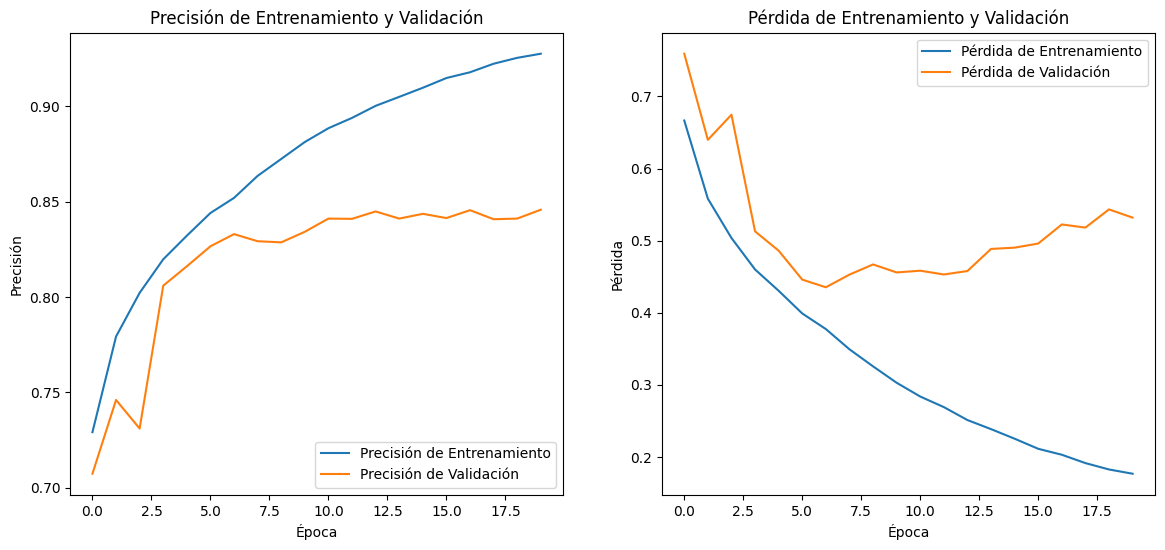


🔮 Realizando y mostrando predicciones...
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


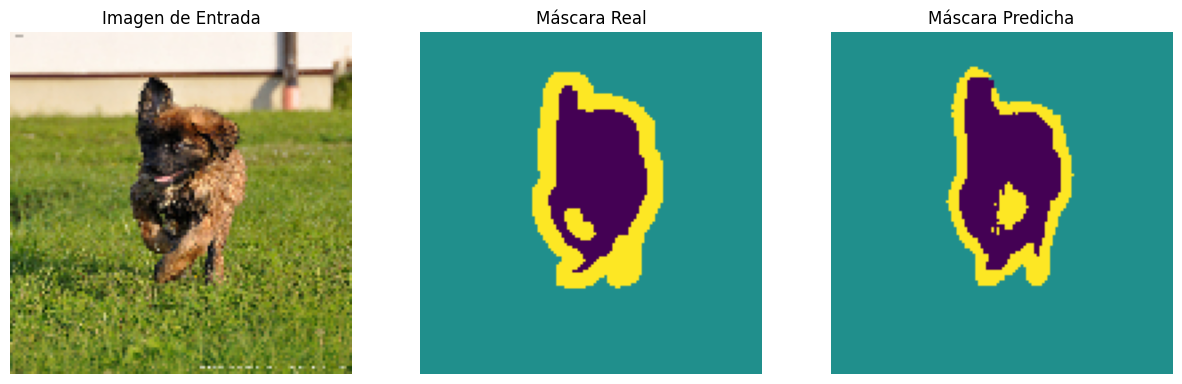

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


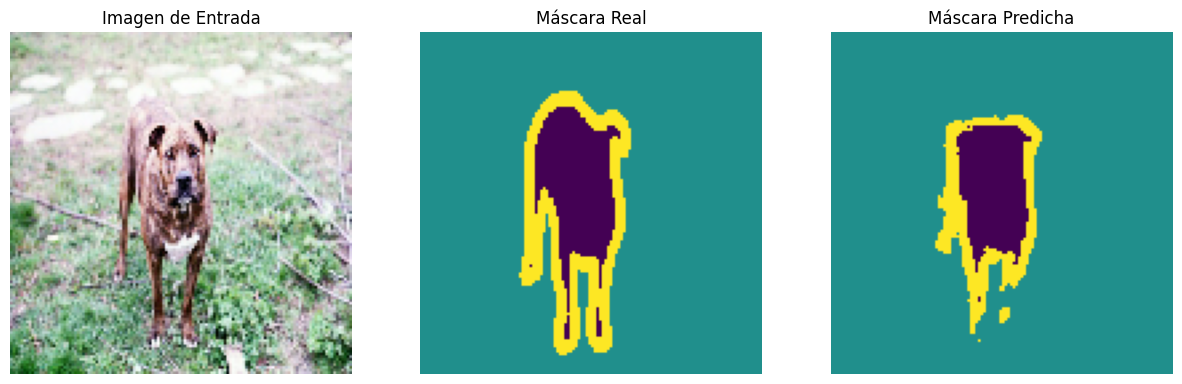

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


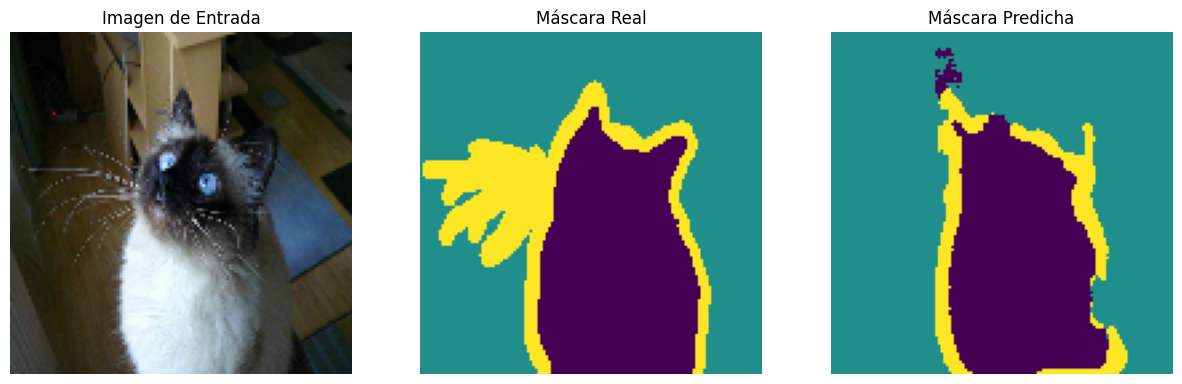

In [ ]:
import matplotlib.pyplot as plt
import tensorflow as tf

# --- PASO 5.1: VISUALIZAR EL HISTORIAL DE ENTRENAMIENTO ---
print("📈 Graficando el historial de entrenamiento...")

# La variable 'model_history' contiene la información de la pérdida (loss) y precisión (accuracy) de cada época.
loss = model_history.history['loss']
val_loss = model_history.history['val_loss']
accuracy = model_history.history['accuracy']
val_accuracy = model_history.history['val_accuracy']

# Usamos la variable EPOCHS que definimos antes
epochs_range = range(EPOCHS)

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, accuracy, label='Precisión de Entrenamiento')
plt.plot(epochs_range, val_accuracy, label='Precisión de Validación')
plt.legend(loc='lower right')
plt.title('Precisión de Entrenamiento y Validación')
plt.xlabel('Época')
plt.ylabel('Precisión')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Pérdida de Entrenamiento')
plt.plot(epochs_range, val_loss, label='Pérdida de Validación')
plt.legend(loc='upper right')
plt.title('Pérdida de Entrenamiento y Validación')
plt.xlabel('Época')
plt.ylabel('Pérdida')

plt.show()


# --- PASO 5.2: VISUALIZAR PREDICCIONES EN DATOS DE PRUEBA ---
print("\n🔮 Realizando y mostrando predicciones...")

def create_mask(pred_mask):
  """Convierte la salida del modelo en una máscara de un solo canal."""
  pred_mask = tf.argmax(pred_mask, axis=-1)
  pred_mask = pred_mask[..., tf.newaxis]
  return pred_mask[0]

def display_predictions(dataset=None, num=1):
  """Muestra la imagen original, la máscara real y la máscara predicha."""
  if dataset:
    for image, mask in dataset.take(num):
      pred_mask = model.predict(image)
      plt.figure(figsize=(15, 5))

      display_list = [image[0], mask[0], create_mask(pred_mask)]
      title = ['Imagen de Entrada', 'Máscara Real', 'Máscara Predicha']

      for i in range(3):
        plt.subplot(1, 3, i+1)
        plt.title(title[i])
        plt.imshow(tf.keras.utils.array_to_img(display_list[i]), cmap='viridis')
        plt.axis('off')
      plt.show()

# Mostramos 3 ejemplos del set de datos de prueba
display_predictions(test_batches, 3)


In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# --- PASO 2.1: DEFINIR LAS FUNCIONES DE PREPROCESAMIENTO (VERSIÓN CORREGIDA) ---
print("⚙️ Definiendo funciones de preprocesamiento (versión corregida)...")

# Definimos las mismas constantes
IMG_WIDTH = 128
IMG_HEIGHT = 128
BATCH_SIZE = 16
OUTPUT_CHANNELS = 3

def normalize(input_image, input_mask):
  input_image = tf.cast(input_image, tf.float32) / 255.0
  input_mask -= 1
  return input_image, input_mask

# 🔥 CORRECCIÓN CLAVE: Modificamos la función de Data Augmentation
@tf.function
def random_jitter(input_image, input_mask):
  # Redimensionamos a un tamaño un poco más grande
  input_image = tf.image.resize(input_image, [144, 144], method='nearest')
  input_mask = tf.image.resize(input_mask, [144, 144], method='nearest')

  # Concatenamos temporalmente en el último eje (canal)
  # Pasamos de (144,144,3) y (144,144,1) a (144,144,4)
  stacked_image = tf.concat([input_image, tf.cast(input_mask, dtype=input_image.dtype)], axis=-1)

  # Hacemos un solo corte aleatorio
  cropped_image = tf.image.random_crop(stacked_image, size=[IMG_HEIGHT, IMG_WIDTH, 4])

  # Separamos de nuevo la imagen y la máscara
  input_image = cropped_image[:, :, :3]
  input_mask = cropped_image[:, :, 3:]

  # Volteo aleatorio (esto ya funcionaba bien)
  if tf.random.uniform(()) > 0.5:
    input_image = tf.image.flip_left_right(input_image)
    input_mask = tf.image.flip_left_right(input_mask)

  return input_image, tf.cast(input_mask, dtype=tf.uint8) # Devolvemos la máscara a su tipo original

# Las demás funciones se mantienen igual
def load_image_train_augmented(datapoint):
  input_image = datapoint['image']
  input_mask = datapoint['segmentation_mask']
  input_image, input_mask = random_jitter(input_image, input_mask)
  input_image, input_mask = normalize(input_image, input_mask)
  return input_image, input_mask

def load_image_test(datapoint):
  input_image = tf.image.resize(datapoint['image'], (IMG_HEIGHT, IMG_WIDTH))
  input_mask = tf.image.resize(datapoint['segmentation_mask'], (IMG_HEIGHT, IMG_WIDTH), method='nearest')
  input_image, input_mask = normalize(input_image, input_mask)
  return input_image, input_mask

print("✅ Funciones corregidas.")

# --- RE-ENTRENAMIENTO (Este código no cambia) ---
print("\n🏗️ Construyendo un nuevo modelo para el re-entrenamiento...")
model_aug = unet_model(OUTPUT_CHANNELS) # Asume que la función unet_model ya fue definida
model_aug.compile(optimizer='adam',
                  loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
                  metrics=['accuracy'])

print("\n🚀 Iniciando el re-entrenamiento con Data Augmentation corregido...")
EPOCHS = 30
model_history_aug = model_aug.fit(
    dataset['train'].map(load_image_train_augmented, num_parallel_calls=tf.data.AUTOTUNE).shuffle(1000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE),
    epochs=EPOCHS,
    validation_data=dataset['test'].map(load_image_test, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
)

print("\n🎉 ¡Re-entrenamiento completado!")

⚙️ Definiendo funciones de preprocesamiento (versión corregida)...
✅ Funciones corregidas.

🏗️ Construyendo un nuevo modelo para el re-entrenamiento...

🚀 Iniciando el re-entrenamiento con Data Augmentation corregido...
Epoch 1/30
230/230 ━━━━━━━━━━━━━━━━━━━━ 21s 31ms/step - accuracy: 0.6574 - loss: 0.7952 - val_accuracy: 0.7242 - val_loss: 0.7087
Epoch 2/30
230/230 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - accuracy: 0.7423 - loss: 0.6320 - val_accuracy: 0.7771 - val_loss: 0.5770
Epoch 3/30
230/230 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - accuracy: 0.7686 - loss: 0.5747 - val_accuracy: 0.8025 - val_loss: 0.5128
Epoch 4/30
230/230 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - accuracy: 0.7902 - loss: 0.5286 - val_accuracy: 0.8103 - val_loss: 0.4861
Epoch 5/30
230/230 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - accuracy: 0.7996 - loss: 0.5019 - val_accuracy: 0.7935 - val_loss: 0.5189
Epoch 6/30
230/230 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - accuracy: 0.8085 - loss: 0.4826 - val_accuracy: 0.8192 - val_loss: 0.4597
Epoch

⚙️ Re-creando el pipeline de datos de prueba para la visualización...
✅ Pipeline de prueba listo.

📈 Graficando el historial del re-entrenamiento...


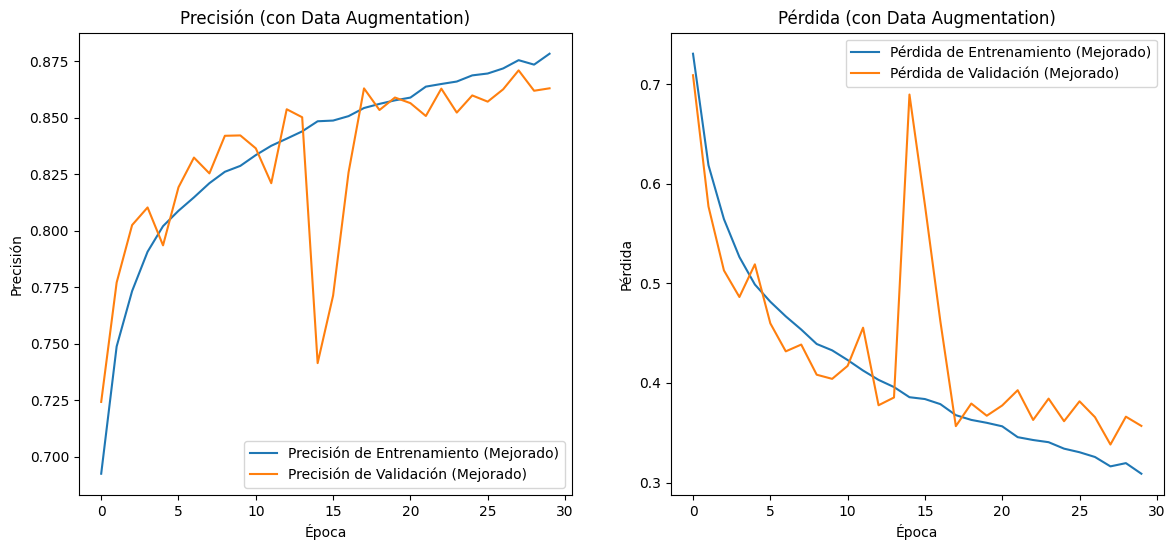


🔮 Realizando y mostrando predicciones con el modelo mejorado...
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


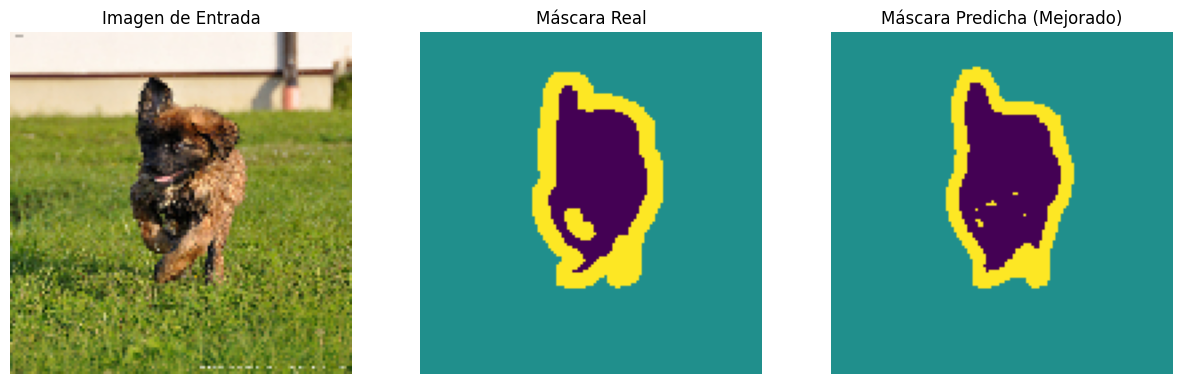

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


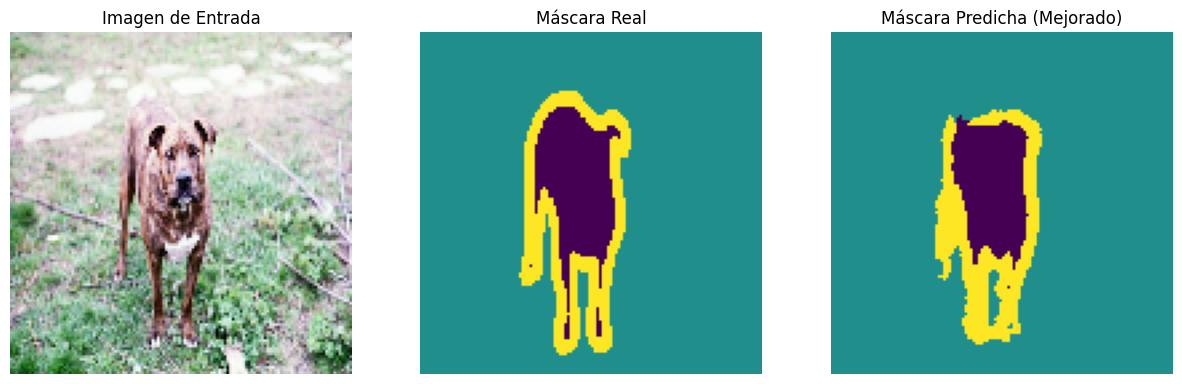

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


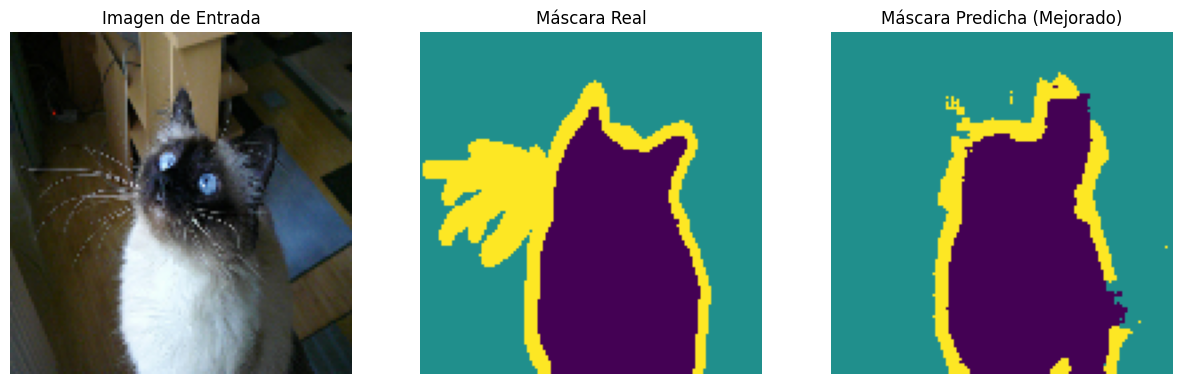

In [ ]:
import matplotlib.pyplot as plt
import tensorflow as tf

# --- PASO PREVIO: RE-CREAR EL PIPELINE DE DATOS DE PRUEBA ---
# 🔥 CORRECCIÓN: Añadimos estas líneas para que la celda sepa qué es 'test_batches_aug'.
# Esto no vuelve a procesar todo, solo redefine la "tubería".
print("⚙️ Re-creando el pipeline de datos de prueba para la visualización...")

# Asegúrate de que las variables 'dataset', 'load_image_test' y 'BATCH_SIZE'
# fueron definidas en celdas anteriores y ejecutadas en esta sesión.
test_batches_aug = dataset['test'].map(load_image_test, num_parallel_calls=tf.data.AUTOTUNE) \
    .batch(BATCH_SIZE) \
    .prefetch(buffer_size=tf.data.AUTOTUNE)

print("✅ Pipeline de prueba listo.")


# --- PASO 6.1: VISUALIZAR EL HISTORIAL DE ENTRENAMIENTO ---
print("\n📈 Graficando el historial del re-entrenamiento...")

loss = model_history_aug.history['loss']
val_loss = model_history_aug.history['val_loss']
accuracy = model_history_aug.history['accuracy']
val_accuracy = model_history_aug.history['val_accuracy']

epochs_range = range(EPOCHS)

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, accuracy, label='Precisión de Entrenamiento (Mejorado)')
plt.plot(epochs_range, val_accuracy, label='Precisión de Validación (Mejorado)')
plt.legend(loc='lower right')
plt.title('Precisión (con Data Augmentation)')
plt.xlabel('Época')
plt.ylabel('Precisión')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Pérdida de Entrenamiento (Mejorado)')
plt.plot(epochs_range, val_loss, label='Pérdida de Validación (Mejorado)')
plt.legend(loc='upper right')
plt.title('Pérdida (con Data Augmentation)')
plt.xlabel('Época')
plt.ylabel('Pérdida')

plt.show()


# --- PASO 6.2: VISUALIZAR LAS NUEVAS PREDICCIONES ---
print("\n🔮 Realizando y mostrando predicciones con el modelo mejorado...")

# La función 'create_mask' ya debería estar definida de antes.
def display_new_predictions(dataset=None, num=1):
  if dataset:
    for image, mask in dataset.take(num):
      pred_mask = model_aug.predict(image)

      plt.figure(figsize=(15, 5))
      display_list = [image[0], mask[0], create_mask(pred_mask)]
      title = ['Imagen de Entrada', 'Máscara Real', 'Máscara Predicha (Mejorado)']

      for i in range(3):
        plt.subplot(1, 3, i+1)
        plt.title(title[i])
        plt.imshow(tf.keras.utils.array_to_img(display_list[i]), cmap='viridis')
        plt.axis('off')
      plt.show()

# Mostramos 3 ejemplos del set de datos de prueba
display_new_predictions(test_batches_aug, 3)

In [ ]:
# --- PASO FINAL: GUARDAR EL PROGRESO EN GITHUB ---

# 1. Configura tu identidad en Git (solo necesitas hacerlo una vez por sesión)
#    🔥 Reemplaza con tu nombre de usuario y correo de GitHub
!git config --global user.name "LitzyReyes"
!git config --global user.email "167.reyes.litzy@gmail.com"

# 2. Revisa qué archivos has modificado.
#    El notebook aparecerá como modificado.
print("🔎 Archivos modificados en tu taller (Colab):")
!git status

# 3. Añade los cambios al "área de preparación" (staging area).
#    El punto "." significa "todos los archivos modificados en esta carpeta".
print("\n➕ Añadiendo los cambios para guardarlos...")
!git add .

# 4. Crea el "commit": una instantánea de tu trabajo con un mensaje descriptivo.
print("\n📝 Creando el punto de guardado (commit)...")
!git commit -m "Fase 1 completada: Modelo U-Net funcional en PASCAL VOC"

# 5. Sube ("push") tus cambios desde Colab a tu repositorio en GitHub.
print("\n⬆️ Subiendo los cambios a GitHub...")
!git push

print("\n\n✅ ¡Éxito! Tu notebook y cualquier otro cambio han sido guardados en tu repositorio de GitHub.")

🔎 Archivos modificados en tu taller (Colab):
fatal: not a git repository (or any of the parent directories): .git

➕ Añadiendo los cambios para guardarlos...
fatal: not a git repository (or any of the parent directories): .git

📝 Creando el punto de guardado (commit)...
fatal: not a git repository (or any of the parent directories): .git

⬆️ Subiendo los cambios a GitHub...
fatal: not a git repository (or any of the parent directories): .git


✅ ¡Éxito! Tu notebook y cualquier otro cambio han sido guardados en tu repositorio de GitHub.


In [ ]:
# Nos aseguramos de estar en la carpeta del repositorio
%cd /content/PROYECTO-BIOMETRICA_OCULAR

# Preguntamos a Git por su estado
!git status

[Errno 2] No such file or directory: '/content/PROYECTO-BIOMETRICA_OCULAR'
/content
fatal: not a git repository (or any of the parent directories): .git
